## Resolución Espectral

Supongamos que se muestrea una señal a 1000 Hz. Tomamos distinta cantidad de muestras.

|   N    | t obs (ms)            | Δf (Hz) |
| :--:   | :-------------------: | :-----: |
|  128   |         128 ms        |  7.8125 |
|  256   |         256 ms        |  3.906  |
| 1024   |        1024 ms        |  0.976  |

Cuanto más largo es el tiempo observado (t obs), más estrecho es el espaciado entre los 'bins' de frecuencia (Δf). Es decir que el espectro se vuelve más "detallado".


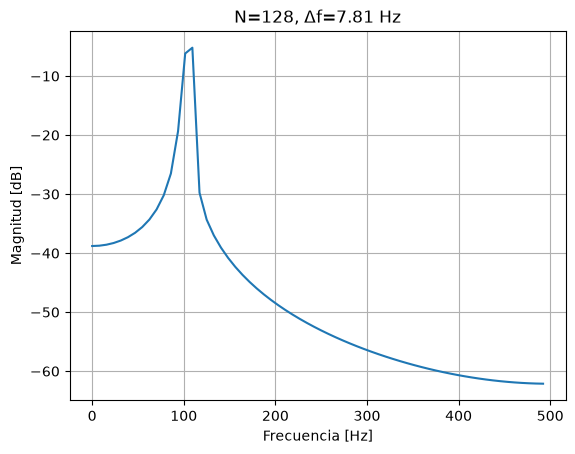

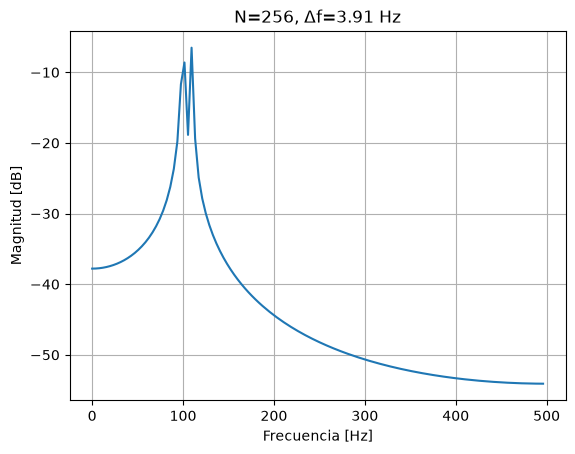

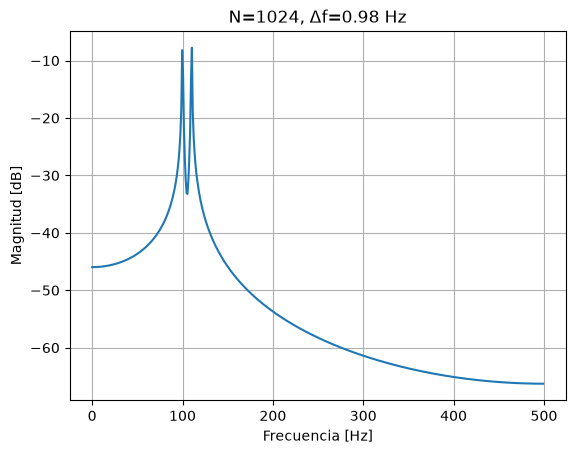

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000  # frecuencia de muestreo
f1, f2 = 100, 110  # dos senoidales cercanas (10 Hz de diferencia)

# Comparar distintos tamaños de ventana
for N in [128, 256, 1024]:
    t = np.arange(N) / fs
    x = np.sin(2*np.pi*f1*t) + np.sin(2*np.pi*f2*t)
    X = np.fft.fft(x, n=N)
    f = np.arange(N) * fs / N

    plt.figure()
    plt.plot(f[:N//2], 20*np.log10(np.abs(X[:N//2])/N))
    plt.title(f"N={N}, Δf={fs/N:.2f} Hz")
    plt.xlabel("Frecuencia [Hz]")
    plt.ylabel("Magnitud [dB]")
    plt.grid(True)
    plt.show()


### ¿Qué se observa?:

- Con N=128: los dos picos (100 Hz y 110 Hz) están casi pegados, no se distinguen.

- Con N=1024: aparecen claramente separados.

Esto visualiza la resolución espectral en acción.

## Leakage y Scalloping Loss

La DFT asume periodicidad, o sea que la ventana que tomamos se replica indefinidamente. El final de la ventana no encaja con su inicio, esto produce fuga hacia otros bins aledaños (Leakage).

Ocurre cuando el valor asociado a una cierta componente de frecuencia de la señal, no coincide exactamente con un bin calculado por la DFT.

La energía se reparte entre bins vecinos, por lo que la amplitud del principal se reduce (Scalloping Loss).

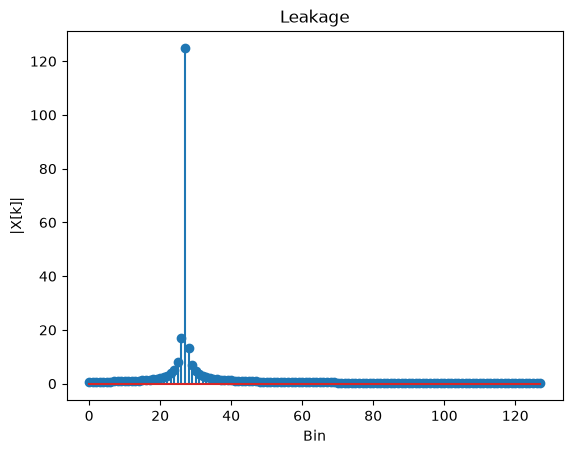

Amplitud máxima: 125.03681566140253


In [2]:
fs = 1000
N = 256
# f0 = 10*fs/N   # coincide con un bin
f0 = 105  # No coincide con un bin
n = np.arange(N)
x = np.sin(2*np.pi*f0*n/fs)
X = np.fft.fft(x)

plt.stem(np.abs(X[:N//2]))
plt.title("Leakage")
plt.xlabel("Bin"); plt.ylabel("|X[k]|"); plt.show()
amplitud = np.amax(np.abs(X[:N//2]))
print(f"Amplitud máxima: {amplitud}")

## Time Windowing

Aplicar una ventana en el tiempo. Cada ventana tiene un comportamiento diferente, pero el objetivo de todas ellas es atenuar los lóbulos laterales. Esto lo hacen a costa de ensanchar el central.

C:\Users\Martin\AppData\Local\Temp\ipykernel_4520\3015723172.py:7: RuntimeWarning: divide by zero encountered in log10
  plt.plot(20*np.log10(np.abs(W[:512])/np.max(np.abs(W))), label=wtype)


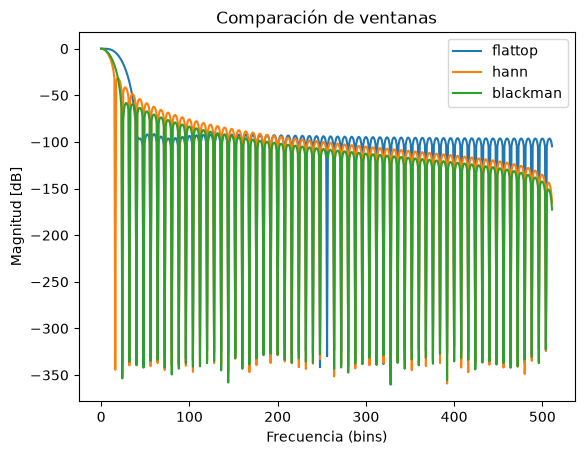

In [8]:
from scipy.signal import get_window

N = 128
for wtype in ['flattop', 'hann', 'blackman']:
    w = get_window(wtype, N)
    W = np.fft.fft(w, 1024)
    plt.plot(20*np.log10(np.abs(W[:512])/np.max(np.abs(W))), label=wtype)

plt.title("Comparación de ventanas")
plt.xlabel("Frecuencia (bins)"); plt.ylabel("Magnitud [dB]")
plt.legend(); plt.show()


## Cómo trabaja el algoritmo de la FFT (Radix-2, Diezmado en Tiempo)
### Descomposición en señales más pequeñas
La FFT parte de una señal de N muestras y la descompone repetidamente en dos señales de N/2 muestras:
- una con las muestras pares,
- otra con las muestras impares.

Este proceso se repite en cascada hasta llegar a bloques de 2 muestras.
En ese punto, cada bloque de 2 puede transformarse directamente usando la fórmula de la DFT de 2 puntos, que es justamente la operación _“butterfly”_.

Para que el algoritmo funcione eficientemente, las muestras deben reordenarse de forma especial:
el índice de cada muestra se invierte en binario (_bit reversal_).
Este reordenamiento garantiza que, al combinar los resultados hacia atrás, las mariposas se apliquen entre los pares correctos.


### Transformación al dominio de frecuencia

Cuando la descomposición llega a los bloques de 2 muestras, cada uno se transforma mediante la DFT de 2 puntos:
$ X_0=a+b$ , $X_1=a−b$
 
donde $a$ y $b$ son las dos muestras del bloque.
Estas son las primeras mariposas: la combinación básica de suma y diferencia.
En cada nivel posterior del algoritmo, los resultados de bloques más pequeños se combinan de a pares usando factores complejos

${W}_{N}^{k} = e^{-j2\pi k/N} $

conocidos como twiddle factors, que introducen los desplazamientos de fase correspondientes.
### Recomposición del espectro completo
A medida que el algoritmo avanza, los resultados parciales se van recombinando, cada etapa fusiona dos espectros de tamaño N/2 para formar uno de N.
#### Intuitivamente:
En el dominio del tiempo, combinar pares e impares equivale a intercalar las muestras.

En el dominio de la frecuencia, eso se traduce en:
* Intercalar ceros → replicar el espectro.
* Desplazar (shift) → multiplicar por una exponencial compleja (una senoidal).


Es decir: lo que en el tiempo sería intercalar o desplazar, en la frecuencia se realiza como producto con senoidales de fase.

Esa es exactamente la operación que realizan las mariposas con sus twiddle factors: combinan los sub-espectros de forma tal que reconstruyen el espectro total, aplicando las rotaciones de fase correctas en cada etapa.


In [4]:
import numpy as np

# Señal original
x = np.array([82, 44, 62, 79, 92, 74, 18, 41], dtype=complex)

# "Decimación" en el tiempo: pares e impares
x0 = x[0::2]  # muestras pares
x1 = x[1::2]  # muestras impares

# FFTs de longitud N/2
X0 = np.fft.fft(x0)
X1 = np.fft.fft(x1)

# Constantes
N = 8
k = np.arange(N//2)
W = np.exp(2j * np.pi / N)

# Combinación según mariposas (Radix-2)
X_upper = X0 + W**(-k) * X1
X_lower = X0 - W**(-k) * X1

# Resultado total de 8 puntos
X_manual = np.concatenate([X_upper, X_lower])

# Verificación con FFT estándar
X_fft = np.fft.fft(x)

# Mostrar resultados
np.set_printoptions(precision=3, suppress=True)
print("Resultado manual:")
print(X_manual)
print("\nResultado fft(x):")
print(X_fft)


Resultado manual:
[492.    +0.j    -58.083-49.657j  94.    +2.j     38.083+38.343j
  16.    +0.j     38.083-38.343j  94.    -2.j    -58.083+49.657j]

Resultado fft(x):
[492.    +0.j    -58.083-49.657j  94.    +2.j     38.083+38.343j
  16.    +0.j     38.083-38.343j  94.    -2.j    -58.083+49.657j]
